# Escenarios sintéticos de los ETF: planes 2, 3 y 4

Lee los CSV que escribe `python -m uvr_loan.synthetic` (`results/synthetic/prices.csv`, `results/synthetic/<escenario>/<plan>.csv` y `results/synthetic/summary.csv`).

Solo cambian los precios de los ETF desde t0; la UVR, las tasas de CDT, el FIC y los pagos son los históricos. Cada ETF sigue, desde su precio real en t0 (t = m / 12 años):

log P_m = log P_0 + drift · t + amplitud · sin(2π m / periodo) + σ · W_m (+ log(1 − caída) desde el mes de la caída)

con W un movimiento browniano mensual. Todos los escenarios usan los mismos números aleatorios (una semilla), así que solo difieren en su parte determinística. Los parámetros están en `synthetic_etfs` de `config/assumptions.yaml`.

Para cada escenario, una figura con:

- **Precios de los ETF** (índice = 100 en t0). Las líneas punteadas verticales son las revisiones; las barras de abajo marcan los meses en que el plan 4 no tiene dinero en ese ETF.
- **Plan 3 y plan 4:** valor del FIC, de los ETF y de los CDT cada mes.
- **Riqueza neta** de los planes 2, 3 y 4.

Al final, la tabla resumen (escenario × plan).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from uvr_loan.cashflows import decision_months
from uvr_loan.config import SYNTHETIC_DIR, load_assumptions

cfg = load_assumptions()
reviews = decision_months(cfg["backtest"])
ETFS = list(cfg["data"]["etfs"])
SCENARIOS = list(cfg["synthetic_etfs"]["scenarios"])
PLANS = {
    "cdt_ladder": "Plan 2 · escalera de CDT",
    "ldi": "Plan 3 · LDI (CDT + ETF)",
    "trend_ldi": "Plan 4 · LDI con filtro de tendencia",
}
# Paleta categórica de referencia (orden fijo): azul, naranja, aguamarina.
COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]
MUTED = "#6b6a63"

prices = pd.read_csv(SYNTHETIC_DIR / "prices.csv")
runs = {
    (s, p): pd.read_csv(SYNTHETIC_DIR / s / f"{p}.csv").set_index("month")
    for s in SCENARIOS
    for p in PLANS
}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e4e3dd", "grid.linewidth": 0.6, "lines.linewidth": 2})

In [2]:
def plot_scenario(scenario):
    fig = plt.figure(figsize=(13, 10), layout="constrained")
    grid = fig.add_gridspec(3, 2)
    ax_price = fig.add_subplot(grid[0, :])
    ax3, ax4 = fig.add_subplot(grid[1, 0]), None
    ax4 = fig.add_subplot(grid[1, 1], sharey=ax3)
    ax_wealth = fig.add_subplot(grid[2, :])
    fig.suptitle(f"Escenario: {scenario}", fontsize=14, x=0.01, ha="left")

    # Precios (índice 100 en t0) y meses en que el plan 4 no tiene dinero en cada ETF
    p = prices[prices["scenario"] == scenario].set_index("month")
    plan4 = runs[(scenario, "trend_ldi")]
    for i, name in enumerate(ETFS):
        color = COLORS[i]
        price = p[f"{name}_price_cop"]
        ax_price.plot(price.index, 100 * price / price.iloc[0], color=color, label=name)
        out = plan4[f"{name}_cop"] <= 0
        band = (0.02 + 0.06 * i, 0.06 + 0.06 * i)
        ax_price.fill_between(out.index, *band, where=out, step="post", color=color, alpha=0.5,
                              transform=ax_price.get_xaxis_transform(), label=f"plan 4 sin {name}")
    for m in reviews:
        ax_price.axvline(m, color=MUTED, linestyle=":", linewidth=0.8)
    ax_price.set_ylabel("Índice (t0 = 100)")
    ax_price.set_title("Precios de los ETF en COP", loc="left")
    ax_price.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))

    # Composición de los planes 3 y 4
    for ax, plan in [(ax3, "ldi"), (ax4, "trend_ldi")]:
        r = runs[(scenario, plan)]
        for column, label, color in zip(["fic_cop", "etf_cop", "cdt_cop"], ["FIC", "ETF", "CDT"], COLORS, strict=True):
            ax.plot(r.index, r[column] / 1e6, color=color, label=label)
        ax.set_title(PLANS[plan], loc="left")
        ax.set_ylabel("Millones de COP")
    ax4.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))

    # Riqueza neta de los planes 2, 3 y 4
    for (plan, label), color in zip(PLANS.items(), [MUTED, COLORS[0], COLORS[1]], strict=True):
        r = runs[(scenario, plan)]
        ax_wealth.plot(r.index, r["wealth_net_cop"] / 1e6, color=color, label=label)
    ax_wealth.set_title("Riqueza neta", loc="left")
    ax_wealth.set_ylabel("Millones de COP")
    ax_wealth.set_xlabel("Mes desde t0")
    ax_wealth.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
    plt.show()

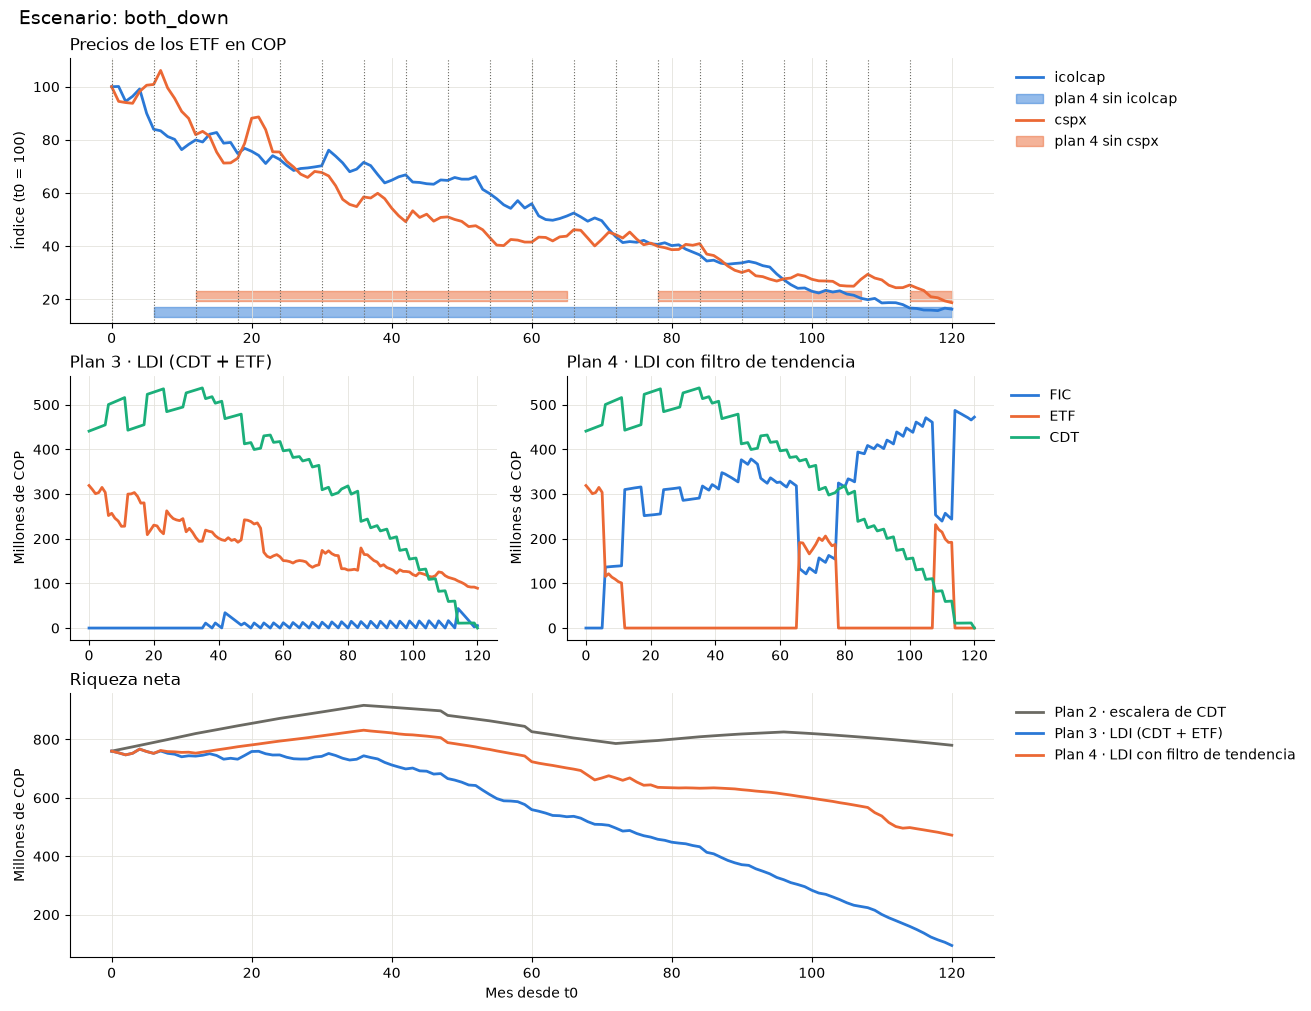

In [3]:
plot_scenario("both_down")

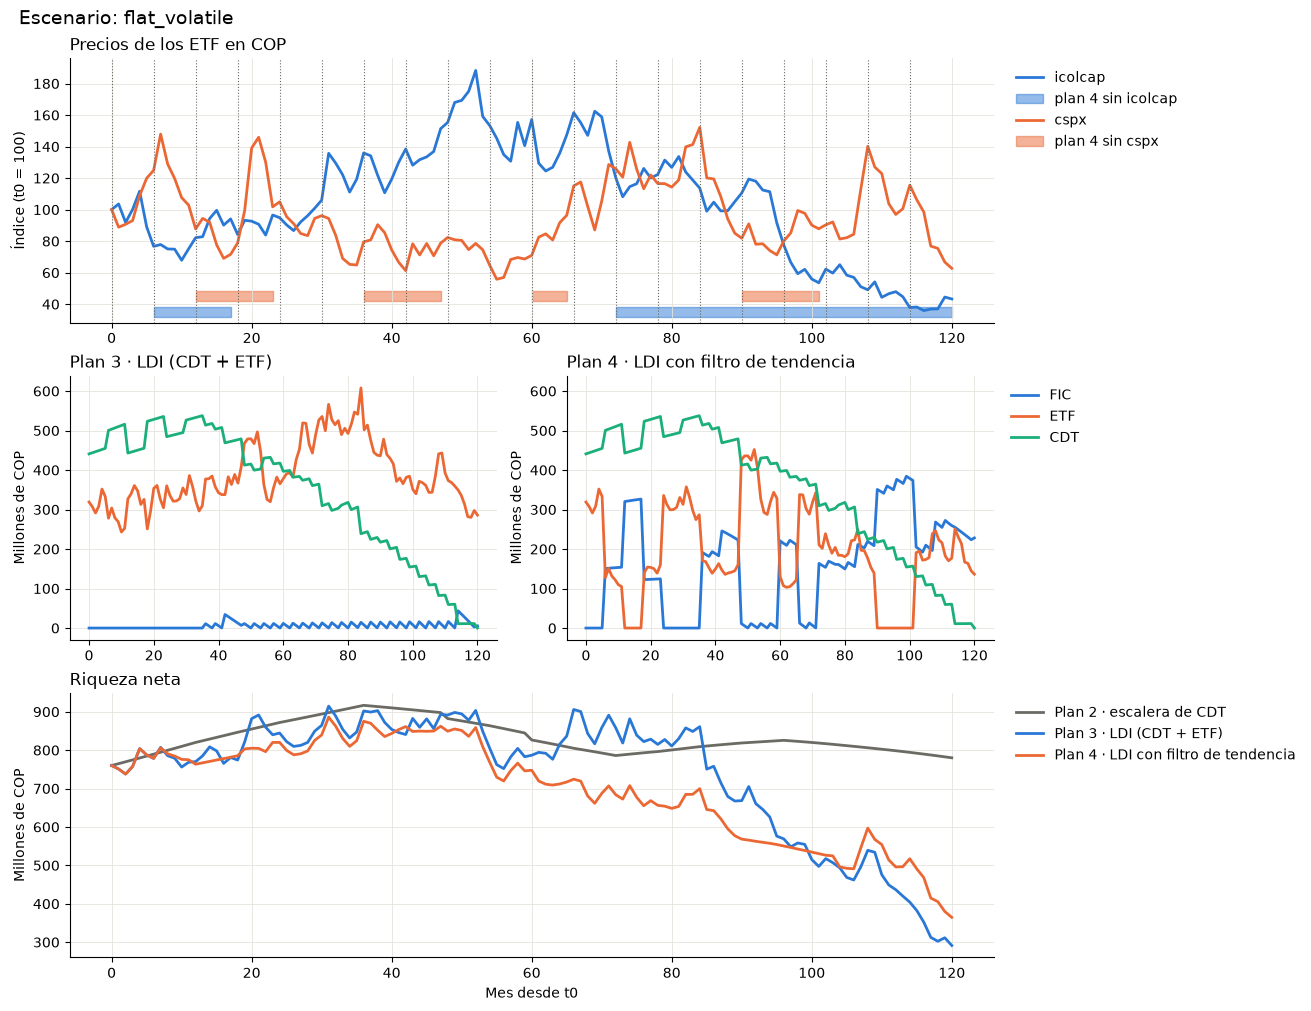

In [4]:
plot_scenario("flat_volatile")

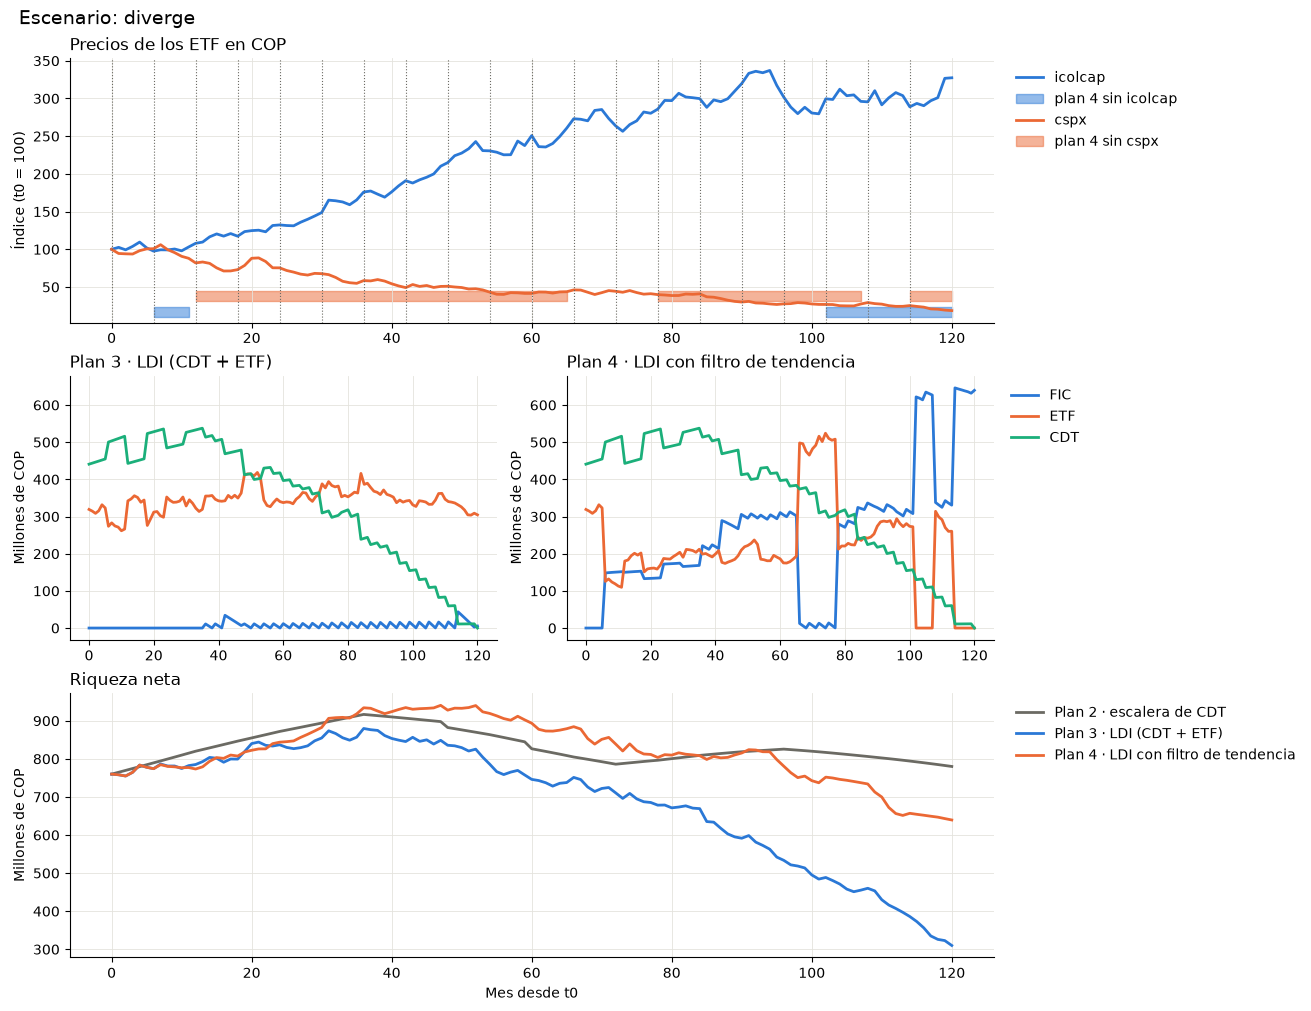

In [5]:
plot_scenario("diverge")

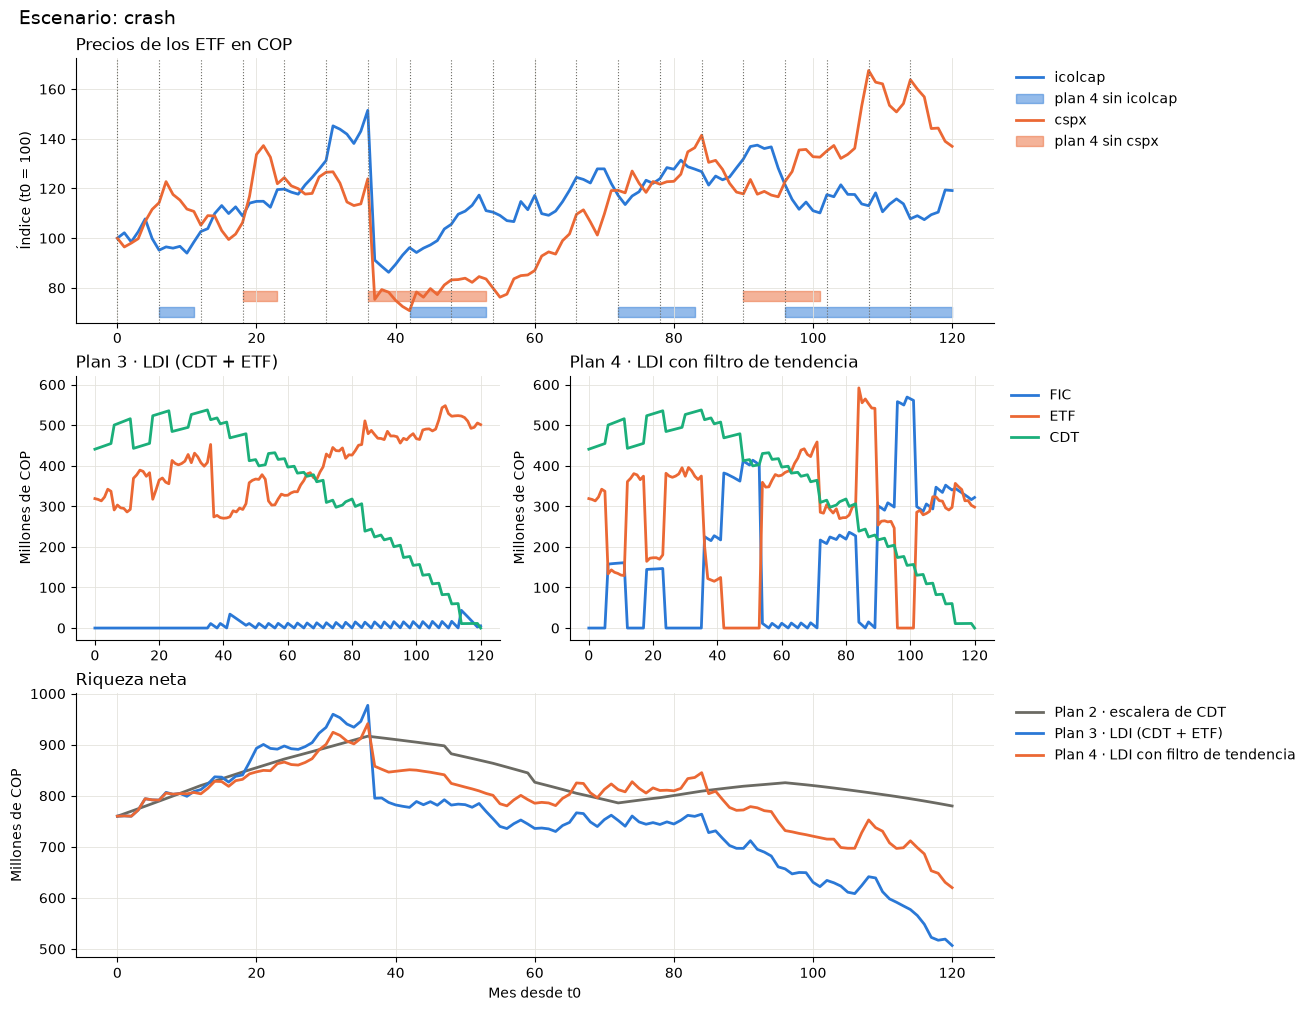

In [6]:
plot_scenario("crash")

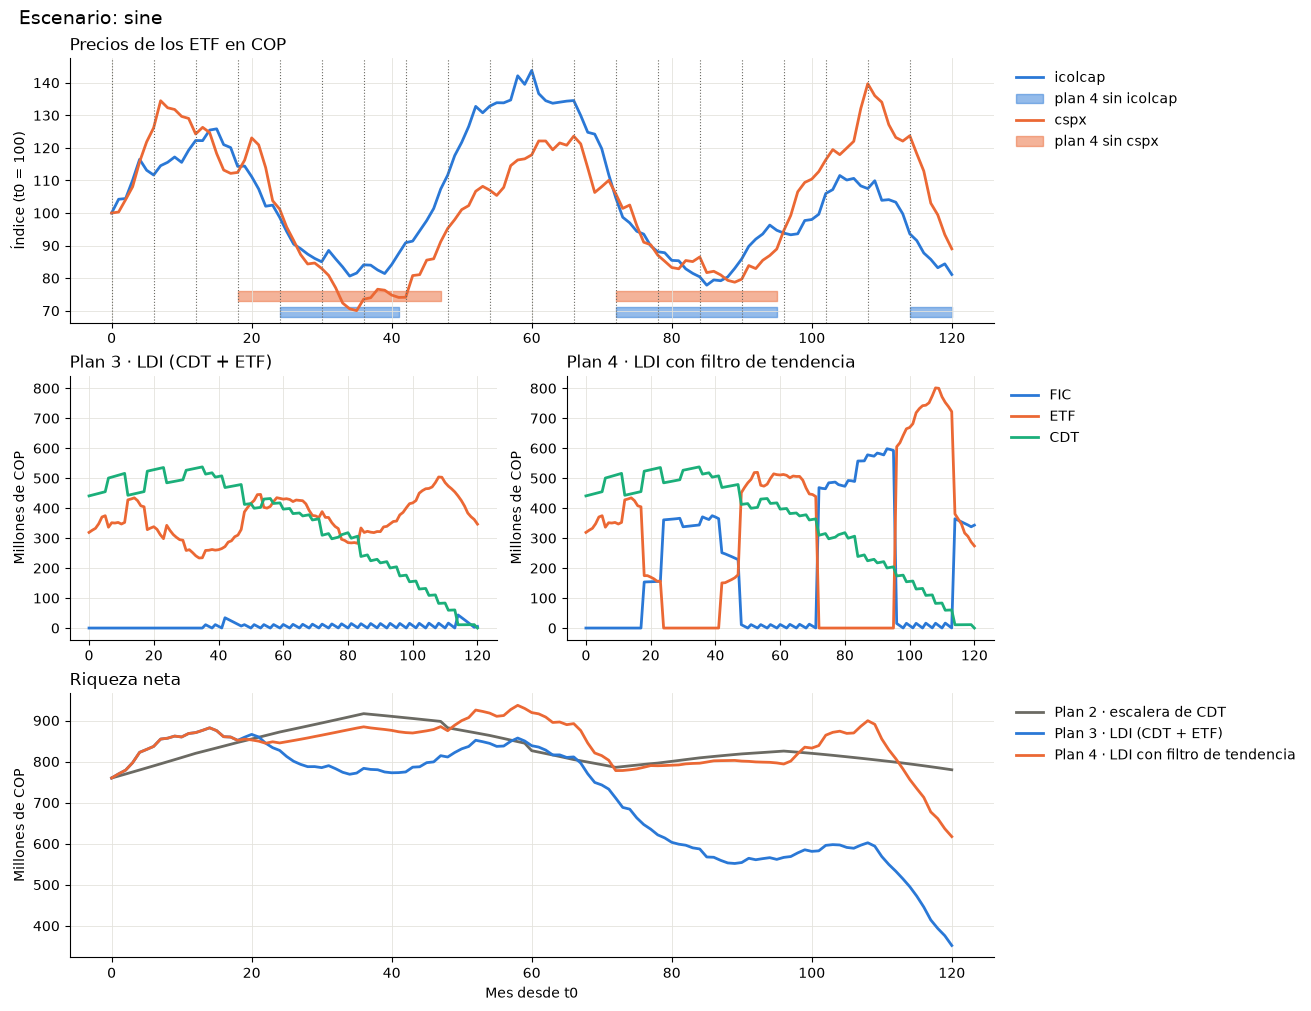

In [7]:
plot_scenario("sine")

## Resumen

Métricas de `backtest.summary` por escenario y plan (riqueza en millones de COP).

In [8]:
summary = pd.read_csv(SYNTHETIC_DIR / "summary.csv")
summary["final_wealth_net_cop"] /= 1e6
summary.pivot(index="scenario", columns="plan", values=["final_wealth_net_cop", "max_drawdown", "annual_return"]).loc[
    SCENARIOS
].round(3)

final_wealth_net_cop                    max_drawdown         \
plan                    cdt_ladder      ldi trend_ldi   cdt_ladder    ldi   
scenario                                                                    
both_down                  780.063   94.513   472.327          0.0  0.214   
flat_volatile              780.063  291.326   364.512          0.0  0.405   
diverge                    780.063  309.940   639.534          0.0  0.146   
crash                      780.063  506.781   620.074          0.0  0.180   
sine                       780.063  352.116   617.221          0.0  0.275   

                        annual_return                   
plan          trend_ldi    cdt_ladder    ldi trend_ldi  
scenario                                                
both_down         0.059         0.079 -0.023     0.048  
flat_volatile     0.243         0.079  0.000     0.024  
diverge           0.063         0.079  0.014     0.060  
crash             0.083         0.079  0.048     0.060  
sine              0.215         0.079  0.019     0.054